# Дослідження поведінки покупців в електронній комерції

**Дисципліна:** Мови програмування для аналізу даних  
**Виконав:** Павлюк Олександр Васильович, група 403-ТН  
**Джерело даних:** Olist Brazilian E-Commerce Public Dataset (відкритий репозиторій `olist/work-at-olist-data`, Kaggle `olistbr/brazilian-ecommerce`)

У цьому ноутбуці виконано повний цикл опрацювання даних: завантаження 7 реляційних таблиць, первинний огляд (EDA), очищення та перевірка аномалій, об’єднання таблиць (`merge`), побудова нових аналітичних ознак, описова статистика, зведені таблиці (`pivot_table`, `crosstab`), кореляційний аналіз і візуалізація засобами Matplotlib та Seaborn.

## 1. Імпорт бібліотек і завантаження вихідних даних

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style('whitegrid')

RAW_DIR = '../data/raw'
PROC_DIR = '../data/processed'
FIG_DIR = '../results/figures'

orders = pd.read_csv(os.path.join(RAW_DIR, 'olist_orders_dataset.csv'))
items = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_items_dataset.csv'))
customers = pd.read_csv(os.path.join(RAW_DIR, 'olist_customers_dataset.csv'))
products = pd.read_csv(os.path.join(RAW_DIR, 'olist_products_dataset.csv'))
payments = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_payments_dataset.csv'))
reviews = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_reviews_dataset.csv'))
cat_trans = pd.read_csv(os.path.join(RAW_DIR, 'product_category_name_translation.csv'))

for name, df_tmp in [
    ('orders', orders), ('items', items), ('customers', customers),
    ('products', products), ('payments', payments), ('reviews', reviews), ('cat_trans', cat_trans)
]:
    print(f"{name:12s} | рядків: {df_tmp.shape[0]:7d} | стовпців: {df_tmp.shape[1]:2d} | дублікатів: {df_tmp.duplicated().sum()}")

orders       | рядків:   99441 | стовпців:  8 | дублікатів: 0
items        | рядків:  112650 | стовпців:  7 | дублікатів: 0
customers    | рядків:   99441 | стовпців:  5 | дублікатів: 0
products     | рядків:   32951 | стовпців:  9 | дублікатів: 0
payments     | рядків:  103886 | стовпців:  5 | дублікатів: 0
reviews      | рядків:   99224 | стовпців:  7 | дублікатів: 0
cat_trans    | рядків:      71 | стовпців:  2 | дублікатів: 0


## 2. Первинний огляд структури (EDA)

In [2]:
print("--- Перші 5 рядків таблиці orders ---")
display(orders.head())
print("\n--- Типи та пропуски в orders ---")
orders.info()
print("\n--- Розподіл статусів замовлень ---")
print(orders['order_status'].value_counts())

--- Перші 5 рядків таблиці orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



--- Типи та пропуски в orders ---
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

--- Розподіл статусів замовлень ---
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [3]:
print("--- Описова статистика таблиці items ---")
display(items[['price', 'freight_value']].describe().round(2))
print("\nУнікальних замовлень у items:", items['order_id'].nunique())
print("Унікальних товарів у products:", products['product_id'].nunique())
print("Унікальних покупців (customer_unique_id):", customers['customer_unique_id'].nunique())

--- Описова статистика таблиці items ---


,price,freight_value
count,112650.00,112650.00
mean,120.65,20.03
std,183.63,16.02
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.27
75%,134.90,21.15
max,6735.00,409.68



Унікальних замовлень у items: 98666
Унікальних товарів у products: 32951
Унікальних покупців (customer_unique_id): 96096


## 3. Попереднє опрацювання та очищення даних

На цьому етапі переводимо стовпці дат у формат `datetime`, відбираємо доставлені замовлення з коректними часовими мітками, доповнюємо словник перекладу категорій, заповнюємо поодинокі пропуски у вазі товарів медіаною відповідної категорії та прибираємо повторні відгуки в межах одного замовлення.

In [4]:
# Перетворення текстових дат у datetime
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

print("Пропуски в orders до очищення:")
print(orders.isna().sum())

# Відбір доставлених замовлень без пропусків дати доставки
orders_deliv = orders[orders['order_status'] == 'delivered'].copy()
print("\nДоставлених замовлень:", len(orders_deliv))
print("Серед них без дати доставки:", orders_deliv['order_delivered_customer_date'].isna().sum())

orders_clean = orders_deliv.dropna(subset=['order_delivered_customer_date', 'order_purchase_timestamp']).copy()
orders_clean = orders_clean[orders_clean['order_delivered_customer_date'] >= orders_clean['order_purchase_timestamp']]
print("Залишилось коректних доставлених замовлень:", len(orders_clean))

Пропуски в orders до очищення:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Доставлених замовлень: 96478
Серед них без дати доставки: 8
Залишилось коректних доставлених замовлень: 96470


In [5]:
# Доповнюємо 2 категорії, відсутні у файлі перекладів
extra_trans = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers']
})
cat_trans_full = pd.concat([cat_trans, extra_trans], ignore_index=True).drop_duplicates(subset=['product_category_name'])

products_clean = products.merge(cat_trans_full, on='product_category_name', how='left')
print("Товарів без категорії до заповнення:", products_clean['product_category_name_english'].isna().sum())
products_clean['category'] = products_clean['product_category_name_english'].fillna('unknown')

# Вага товару: заповнюємо поодинокі пропуски медіаною за категорією
med_w = products_clean.groupby('category')['product_weight_g'].transform('median')
products_clean['product_weight_g'] = products_clean['product_weight_g'].fillna(med_w).fillna(products_clean['product_weight_g'].median())

# Дедуплікація відгуків (беремо останній за датою для кожного order_id)
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')
print("Дублікатів order_id у reviews:", reviews.duplicated(subset=['order_id']).sum())
reviews_clean = (
    reviews.sort_values('review_creation_date')
    .drop_duplicates(subset=['order_id'], keep='last')[['order_id', 'review_score']]
)
print("Відгуків після дедуплікації:", len(reviews_clean))

Товарів без категорії до заповнення: 610
Дублікатів order_id у reviews: 551
Відгуків після дедуплікації: 98673


## 4. Об’єднання пов’язаних таблиць та створення аналітичних ознак

Поєднуємо таблиці `orders`, `customers`, агреговані `order_items` (з категоріями товарів), агреговані `payments` та `reviews` у єдину аналітичну таблицю рівня одного замовлення, після чого додаємо 7 похідних ознак.

In [6]:
# Поєднуємо позиції з товарами та агрегуємо на рівень замовлення
items_prod = items.merge(products_clean[['product_id', 'category', 'product_weight_g']], on='product_id', how='left')
main_cat = items_prod.sort_values(['order_id', 'price'], ascending=[True, False]).drop_duplicates('order_id')[['order_id', 'category']]

items_agg = items_prod.groupby('order_id', as_index=False).agg(
    items_count=('order_item_id', 'count'),
    unique_products=('product_id', 'nunique'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_weight_g=('product_weight_g', 'sum')
).merge(main_cat, on='order_id', how='left')

# Агрегуємо платежі
main_pay = payments.sort_values(['order_id', 'payment_value'], ascending=[True, False]).drop_duplicates('order_id')[['order_id', 'payment_type']]
pay_agg = payments.groupby('order_id', as_index=False).agg(
    payment_total=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    payment_parts=('payment_sequential', 'count')
).merge(main_pay, on='order_id', how='left')

# Чотири реляційні об'єднання
df = orders_clean.merge(customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
df = df.merge(items_agg, on='order_id', how='inner')
df = df.merge(pay_agg, on='order_id', how='left')
df = df.merge(reviews_clean, on='order_id', how='left')

df['payment_type'] = df['payment_type'].fillna('not_defined')
df['max_installments'] = df['max_installments'].fillna(1).astype(int)

# Нові аналітичні ознаки
df['order_total'] = (df['total_price'] + df['total_freight']).round(2)
df['freight_share_pct'] = (df['total_freight'] / df['order_total'] * 100).round(2)
df['delivery_days'] = ((df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400).round(2)
df['delivery_delay_days'] = ((df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / 86400).round(2)
df['is_delayed'] = np.where(df['delivery_delay_days'] > 0, 'Затримка', 'Вчасно')
df['purchase_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df['purchase_weekday'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour
df['check_segment'] = pd.cut(
    df['order_total'],
    bins=[0, 60, 150, 350, np.inf],
    labels=['Малий (<60)', 'Середній (60-150)', 'Вище середнього (150-350)', 'Великий (>350)']
)
df['customer_orders_cnt'] = df.groupby('customer_unique_id')['order_id'].transform('count')
df['customer_type'] = np.where(df['customer_orders_cnt'] > 1, 'Повторний', 'Одноразовий')

print("Підсумкова розмірність вітрини:", df.shape)
display(df[['order_id', 'customer_state', 'category', 'order_total', 'freight_share_pct', 'delivery_days', 'is_delayed', 'review_score']].head())

Підсумкова розмірність вітрини: (96470, 33)


,order_id,customer_state,category,order_total,freight_share_pct,delivery_days,is_delayed,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,housewares,38.71,22.53,8.44,Вчасно,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,perfumery,141.46,16.09,13.78,Вчасно,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,auto,179.12,10.73,9.39,Вчасно,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,pet_shop,72.20,37.67,13.21,Вчасно,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,stationery,28.62,30.47,2.87,Вчасно,5.0


## 5. Статистичний аналіз, групування, ранжування та зведені таблиці

In [7]:
# Описова статистика + IQR та асиметрія
num_cols = ['order_total', 'total_price', 'total_freight', 'freight_share_pct', 'items_count', 'delivery_days', 'delivery_delay_days', 'max_installments', 'review_score']
desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['iqr'] = desc['75%'] - desc['25%']
desc['skew'] = df[num_cols].skew()
display(desc[['mean', 'median', 'std', 'min', '25%', '75%', 'max', 'iqr', 'skew']].round(2))

,mean,median,std,min,25%,75%,max,iqr,skew
order_total,159.87,105.28,218.83,9.59,61.85,176.34,13664.08,114.49,9.36
total_price,137.04,86.50,209.05,0.85,45.90,149.90,13440.00,104.00,9.89
total_freight,22.83,17.19,21.74,0.00,13.85,24.05,1794.96,10.20,12.14
freight_share_pct,20.91,18.33,12.57,0.00,11.66,27.58,95.55,15.92,1.06
items_count,1.14,1.00,0.54,1.00,1.00,1.00,21.00,0.00,7.56
delivery_days,12.56,10.22,9.55,0.53,6.77,15.72,209.63,8.95,3.83
delivery_delay_days,-11.18,-11.95,10.18,-146.02,-16.24,-6.39,188.98,9.85,2.01
max_installments,2.93,2.00,2.71,0.00,1.00,4.00,24.00,3.00,1.60
review_score,4.16,5.00,1.28,1.00,4.00,5.00,5.00,1.00,-1.48


In [8]:
# Топ-10 категорій за обігом
cat_agg = df.groupby('category', as_index=False).agg(
    orders_count=('order_id', 'count'),
    total_revenue=('order_total', 'sum'),
    avg_check=('order_total', 'mean'),
    avg_review=('review_score', 'mean')
).sort_values('total_revenue', ascending=False)
cat_agg['revenue_share_pct'] = (cat_agg['total_revenue'] / cat_agg['total_revenue'].sum() * 100).round(2)
cat_agg['rank'] = cat_agg['total_revenue'].rank(ascending=False, method='dense').astype(int)
display(cat_agg.nlargest(10, 'total_revenue').round(2))

,category,orders_count,total_revenue,avg_check,avg_review,revenue_share_pct,rank
43,health_beauty,8613,1413081.37,164.06,4.23,9.16,1
73,watches_gifts,5476,1265330.50,231.07,4.12,8.20,2
7,bed_bath_table,9184,1226459.39,133.54,4.01,7.95,3
67,sports_leisure,7492,1119164.93,149.38,4.24,7.26,4
15,computers_accessories,6511,1032613.52,158.60,4.08,6.70,5
39,furniture_decor,6188,877613.67,141.83,4.08,5.69,6
49,housewares,5680,758811.35,133.59,4.20,4.92,7
20,cool_stuff,3530,692050.84,196.05,4.23,4.49,8
5,auto,3792,669780.97,176.63,4.15,4.34,9
42,garden_tools,3400,563536.38,165.75,4.20,3.65,10


In [9]:
# Зведена таблиця 1: середній чек для Топ-6 категорій у розрізі способу оплати
top6 = cat_agg.nlargest(6, 'total_revenue')['category'].tolist()
pivot_cat_pay = pd.pivot_table(
    df[df['category'].isin(top6) & df['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])],
    index='category', columns='payment_type', values='order_total', aggfunc='mean', fill_value=0
).round(2)
print("Середній чек (BRL) за категорією та способом оплати:")
display(pivot_cat_pay)

# Зведена таблиця 2: розподіл оцінок (1-5) залежно від затримки доставки (%)
ct_delay = (pd.crosstab(df['is_delayed'], df['review_score'], normalize='index') * 100).round(2)
print("\nРозподіл оцінок покупців (%) залежно від вчасності доставки:")
display(ct_delay)

Середній чек (BRL) за категорією та способом оплати:


payment_type,boleto,credit_card,debit_card,voucher
category,,,,
bed_bath_table,120.68,137.46,138.99,108.06
computers_accessories,175.63,155.66,112.66,105.97
furniture_decor,135.20,145.88,114.17,103.51
health_beauty,144.39,171.00,142.76,109.42
sports_leisure,130.13,155.58,160.51,119.54
watches_gifts,179.00,242.03,319.50,185.96



Розподіл оцінок покупців (%) залежно від вчасності доставки:


review_score,1.0,2.0,3.0,4.0,5.0
is_delayed,,,,,
Вчасно,6.59,2.63,7.99,20.36,62.43
Затримка,46.26,7.84,11.38,12.31,22.22


In [10]:
# Аналіз повторних покупців (за customer_unique_id)
cust_lvl = df.groupby('customer_unique_id', as_index=False).agg(
    orders_cnt=('order_id', 'count'),
    total_spent=('order_total', 'sum'),
    avg_order=('order_total', 'mean')
)
cust_lvl['group'] = np.where(cust_lvl['orders_cnt'] > 1, 'Повторні (2+)', 'Одноразові (1)')
rep = cust_lvl.groupby('group', as_index=False).agg(
    customers=('customer_unique_id', 'count'),
    orders=('orders_cnt', 'sum'),
    revenue=('total_spent', 'sum'),
    avg_order=('avg_order', 'mean'),
    avg_ltv=('total_spent', 'mean')
).round(2)
rep['customers_pct'] = (rep['customers'] / len(cust_lvl) * 100).round(2)
display(rep)

,group,customers,orders,revenue,avg_order,avg_ltv,customers_pct
0,Одноразові (1),90549,90549,14558130.11,160.78,160.78,97.0
1,Повторні (2+),2801,5921,864954.62,145.95,308.80,3.0


## 6. Візуалізація даних засобами Matplotlib та Seaborn

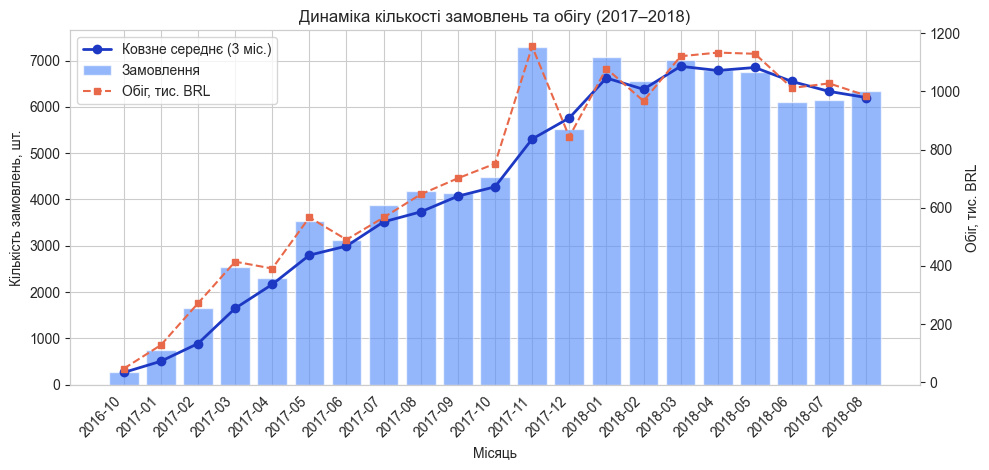

In [11]:
# 6.1 Динаміка замовлень та обігу по місяцях (resample + rolling)
monthly = df.set_index('order_purchase_timestamp').resample('ME').agg(
    orders_count=('order_id', 'count'),
    revenue=('order_total', 'sum')
).reset_index()
monthly['month'] = monthly['order_purchase_timestamp'].dt.strftime('%Y-%m')
monthly = monthly[monthly['orders_count'] >= 50].copy()
monthly['orders_ma3'] = monthly['orders_count'].rolling(3, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(monthly))
ax1.bar(x, monthly['orders_count'], color='#5B8FF9', alpha=0.65, label='Замовлення')
ax1.plot(x, monthly['orders_ma3'], color='#1D39C4', marker='o', linewidth=2, label='Ковзне середнє (3 міс.)')
ax1.set_xticks(x)
ax1.set_xticklabels(monthly['month'], rotation=45, ha='right')
ax1.set_ylabel('Кількість замовлень, шт.')
ax1.set_xlabel('Місяць')

ax2 = ax1.twinx()
ax2.plot(x, monthly['revenue'] / 1000, color='#E8684A', linestyle='--', marker='s', markersize=4, label='Обіг, тис. BRL')
ax2.set_ylabel('Обіг, тис. BRL')
ax2.grid(False)

ax1.set_title('Динаміка кількості замовлень та обігу (2017–2018)')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout()
plt.show()

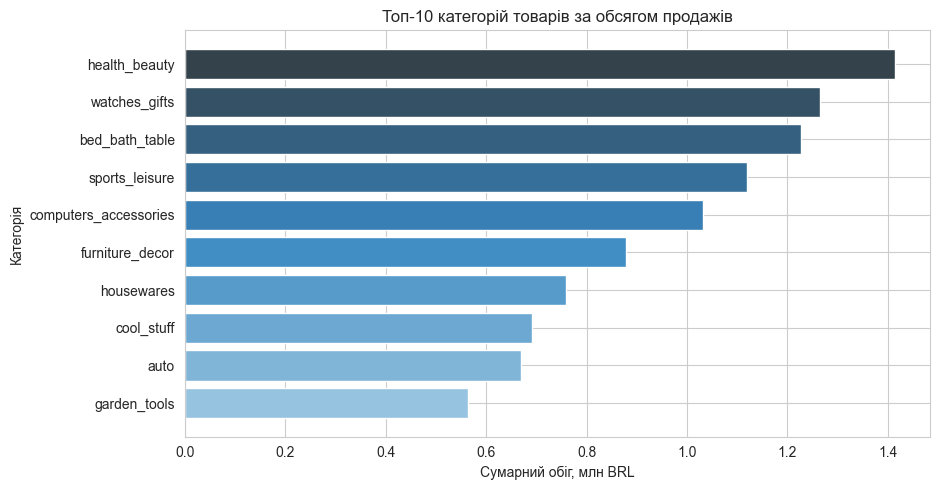

In [12]:
# 6.2 Топ-10 категорій за сумарним обігом
top10 = cat_agg.nlargest(10, 'total_revenue').sort_values('total_revenue', ascending=True)
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(top10['category'], top10['total_revenue'] / 1e6, color=sns.color_palette('Blues_d', 10))
ax.set_xlabel('Сумарний обіг, млн BRL')
ax.set_ylabel('Категорія')
ax.set_title('Топ-10 категорій товарів за обсягом продажів')
plt.tight_layout()
plt.show()

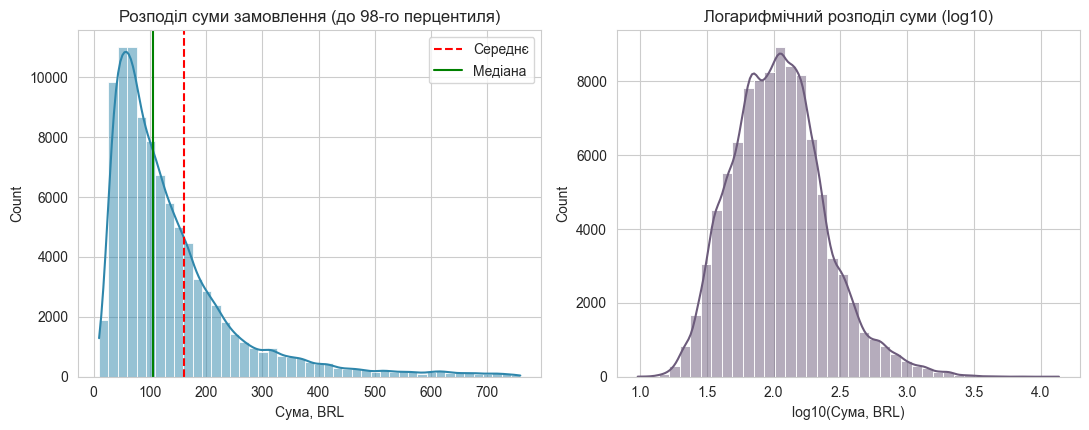

In [13]:
# 6.3 Гістограма та KDE розподілу суми замовлення (98-й перцентиль + log10)
p98 = df['order_total'].quantile(0.98)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sns.histplot(df.loc[df['order_total'] <= p98, 'order_total'], bins=45, kde=True, color='#2E86AB', ax=axes[0])
axes[0].axvline(df['order_total'].mean(), color='red', linestyle='--', label='Середнє')
axes[0].axvline(df['order_total'].median(), color='green', label='Медіана')
axes[0].set_title('Розподіл суми замовлення (до 98-го перцентиля)')
axes[0].set_xlabel('Сума, BRL')
axes[0].legend()

sns.histplot(np.log10(df['order_total'].clip(lower=1)), bins=40, kde=True, color='#6C5B7B', ax=axes[1])
axes[1].set_title('Логарифмічний розподіл суми (log10)')
axes[1].set_xlabel('log10(Сума, BRL)')
plt.tight_layout()
plt.show()

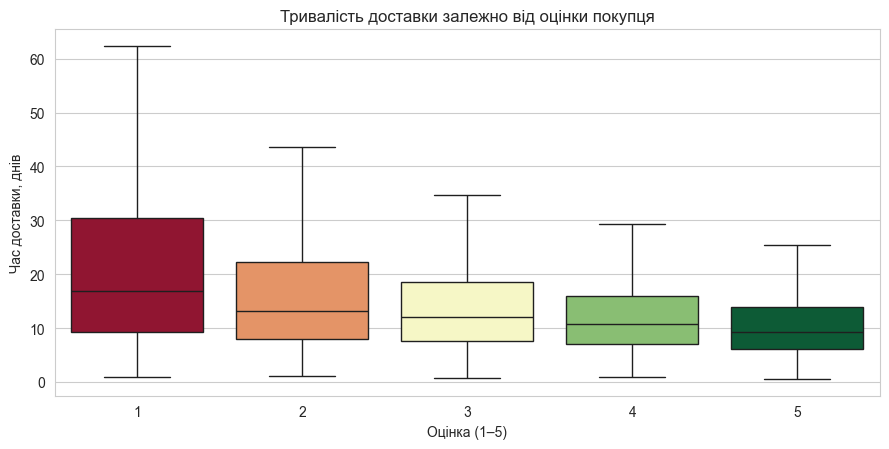

In [14]:
# 6.4 Boxplot: час доставки залежно від оцінки покупця
plot_rev = df.dropna(subset=['review_score']).copy()
plot_rev['review_score'] = plot_rev['review_score'].astype(int)
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.boxplot(data=plot_rev, x='review_score', y='delivery_days', hue='review_score', palette='RdYlGn', legend=False, showfliers=False, ax=ax)
ax.set_title('Тривалість доставки залежно від оцінки покупця')
ax.set_xlabel('Оцінка (1–5)')
ax.set_ylabel('Час доставки, днів')
plt.tight_layout()
plt.show()

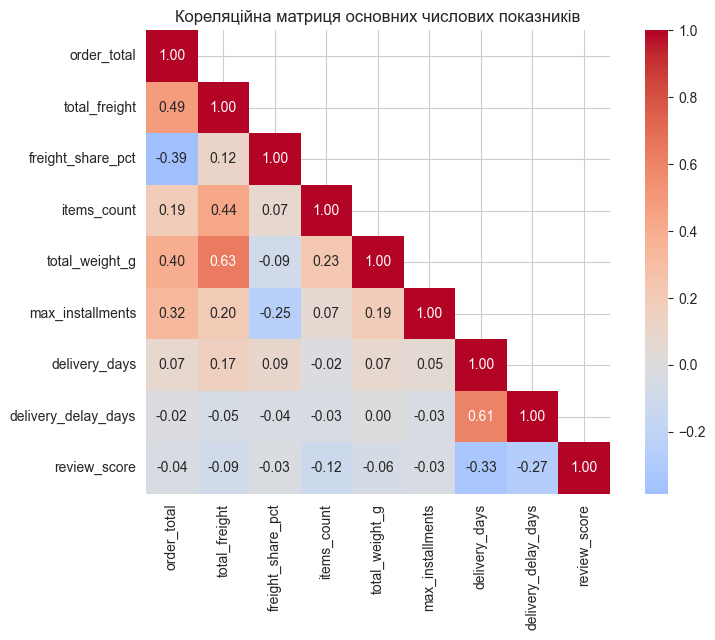

In [15]:
# 6.5 Кореляційна матриця (теплова карта)
corr_cols = ['order_total', 'total_freight', 'freight_share_pct', 'items_count', 'total_weight_g', 'max_installments', 'delivery_days', 'delivery_delay_days', 'review_score']
corr_m = df[corr_cols].corr(method='pearson')
fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr_m, dtype=bool), k=1)
sns.heatmap(corr_m, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Кореляційна матриця основних числових показників')
plt.tight_layout()
plt.show()

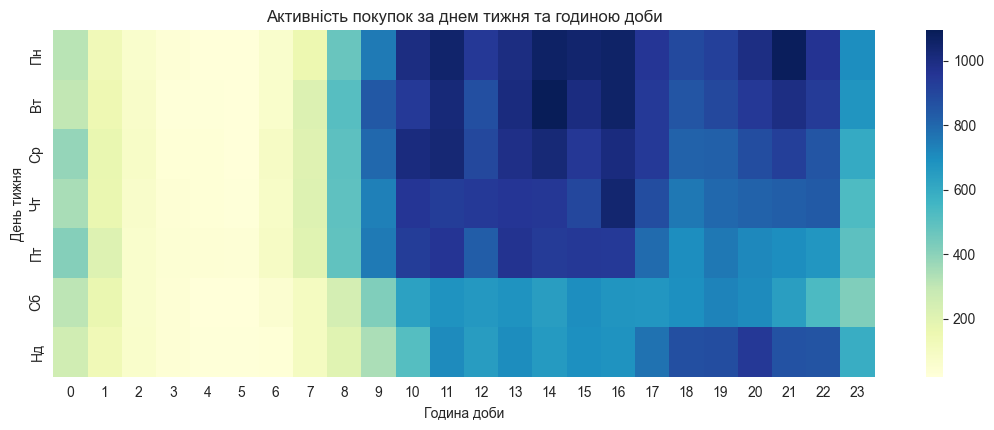

In [16]:
# 6.6 Теплова карта активності покупців за днями тижня та годинами
wd_hr = pd.crosstab(df['purchase_weekday'], df['purchase_hour'])
wd_hr.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.heatmap(wd_hr, cmap='YlGnBu', ax=ax)
ax.set_title('Активність покупок за днем тижня та годиною доби')
ax.set_xlabel('Година доби')
ax.set_ylabel('День тижня')
plt.tight_layout()
plt.show()